# Bank Marketing — Term Deposit Prediction

This notebook predicts which customer will open a term deposit in a bank's telemarketing campaign. The goal is limited: we have a certain call capacity, so we want to sort customers by their "probability of opening" and call the most likely ones.  Data: UCI bank-additional (41,188 customers, 20 variables). Target variable is y ("yes"/"no").  

### Summary of the flow
1. Load and explore the data
2. Derive a few new features, drop the leaking feature
3. Shuffle and split the data into stratified train/test sets
4. Compare four models using cross-validation (CV
5. Tune the best one with Optuna
6. Evaluate honestly on the test set + business metric (lift)
7. Answer the "why" question with SHAP



## 1. Libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      cross_val_score, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_recall_curve, roc_curve, auc,
                             classification_report, confusion_matrix)

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import optuna
import shap

optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42                       # tekrarlanabilirlik için sabit tohum
pd.options.display.float_format = "{:.4f}".format

ModuleNotFoundError: No module named 'ydata_profiling'

## 2. Load the data

In [ ]:

# Load dataset from UCI repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip'
import zipfile, io, urllib.request
resp = urllib.request.urlopen(url)
zf = zipfile.ZipFile(io.BytesIO(resp.read()))
with zf.open('bank-additional/bank-additional-full.csv') as f:
    df = pd.read_csv(f, sep=';')

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset shape: 41,188 rows x 21 columns


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,5191.0000,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,5191.0000,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,5191.0000,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,5191.0000,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,5191.0000,no


In [ ]:
pwd

'C:\\Users\\csume'

In [ ]:
profile = ProfileReport(df,title="Telemarketing Profiling Report")

In [ ]:
profile.to_file("bank_eda_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████████████████████████████████████████████████████████████████████████████| 21/21 [00:00<00:00, 32.61it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
profile

NameError: name 'profile' is not defined

## 3.EDA

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [ ]:
print("sum of the miss values:", df.isnull().sum().sum())
print("duplicated rows:", df.duplicated().sum())
print("\ntarget dist:")
print(df["y"].value_counts(normalize=True))

sum of the miss values: 0
duplicated rows: 12

target dist:
y
no    0.8873
yes   0.1127
Name: proportion, dtype: float64


Only ~11% of the target is "yes". Meaning the data is imbalanced. We need to keep this in mind, because it directly affects the choice of metrics and the interpretation of the results (explained in section 7 below).

## 4. Convert target variable to numeric

In [ ]:
df["y"] = df["y"].map({"yes": 1, "no": 0})
df["y"].head()

0    0
1    0
2    0
3    0
4    0
Name: y, dtype: int64

## 5. feature engineering

We are adding a few meaningful variables. Point to note: in this dataset, the "not previously contacted" status is encoded as 999 in the pdays column (it was -1 in the classic bank-full version). If we use the wrong value, the features we derive will be corrupted, so we process based on 999.

- `pr_contacted`: was the customer contacted before? (yes/no)
- `pdays_clean`: we make 999 a true "missing value" (NaN) so it doesn't mislead as a number
- `campaign_ratio`, `total_contacts`: simple ratios summarizing call intensity

In [ ]:
SENTINEL = 999   # "not called before" value

df["pr_contacted"]   = np.where(df["pdays"] == SENTINEL, 0, 1)
df["pdays_clean"]    = df["pdays"].replace(SENTINEL, np.nan)
df["campaign_ratio"] = df["campaign"] / (df["previous"] + 1)
df["total_contacts"] = df["campaign"] + df["previous"]

print(df["pr_contacted"].value_counts())

pr_contacted
0    39673
1     1515
Name: count, dtype: int64


## 6. Drop the leaking duration column

duration = duration of the last call in seconds. The problem is: we only learn this information after the call has ended. So it is data we don't have at the time of prediction. If we put it in the model, the scores will artificially soar (e.g. ROC-AUC ~0.94), but it will be useless in real life — this is called data leakage. UCI's own documentation also says "discard this for a realistic model".

We are also dropping pdays because we already cleaned it as pdays_clean + pr_contacted.

In [ ]:
df = df.drop(columns=["duration", "pdays"])
print("total nr of the rows:", df.shape[1])
df.head()

NameError: name 'df' is not defined

## 7. Features and target + train/test split

X = inputs, y = target. Then we split the data into two as train and test.  

Two settings are critical:

- **`shuffle=True`**: data is sorted by date; if we don't shuffle, train and test fall into different periods and the "yes" ratio flies off (low in train, high in test). Shuffling removes this problem.
- **`stratify=y`**: keeps the "yes" ratio (~11%) the same in both train and test.

In [ ]:
X = df.drop(columns=["y"])
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, shuffle=True, random_state=SEED)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"train: {X_train.shape[0]} satır, yes ratio {y_train.mean():.3f}")
print(f"test  : {X_test.shape[0]} satır, yes ratio {y_test.mean():.3f}")

train: 32950 satır, yes ratio 0.113
test  : 8238 satır, yes ratio 0.113



## 8. Preprocessing (one-hot encoding)

We need to convert categorical columns (job, month, ...) into numbers. One-hot encoding expands each category into 0/1 columns. For numerical columns, we fill missing values with the median.  We gather this in a single ColumnTransformer and we will place the exact same one in front of every model — this way, all four models compete fairly with exactly the same data.

In [ ]:
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", SimpleImputer(strategy="median"), num_cols),
])

print("categorical:", cat_cols)
print("numerical :", num_cols)

categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
numerical : ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pr_contacted', 'pdays_clean', 'campaign_ratio', 'total_contacts']


## 9. Which metric?

Since the data is imbalanced, metric selection is important:  Accuracy is misleading. If we say "no" to everyone, it will yield 89% accuracy, but we wouldn't find a single customer. Therefore, we do not look at accuracy.  PR-AUC (average precision) — our main metric. It solely focuses on the positive class (yes) and is less affected by imbalance. Random guessing gives ~0.11; we are aiming for ~4 times this.  Lift — speaks the business language: "if we call the top 20% most likely, how many times more deposits do we find compared to random calling?"  ROC-AUC — we report it as a reference (standard in the literature), but we don't rely on it alone because it can seem overly optimistic on imbalanced data.  

## 10. Cross-val

We build four models: a simple Logistic Regression (baseline) and three gradient boosting models (LightGBM, XGBoost, CatBoost). We evaluate them all with 5-fold CV, using PR-AUC.  Why CV? Instead of looking at a single validation set, we divide the data into 5 parts and test a different part each time to get 5 scores. The average is more reliable, and the standard deviation answers the question "is this difference real or just luck?".  All four models turn out to be very close to each other (~0.45-0.47). An important observation: even the simple linear model is very close to the boosting models. This shows that the signal in the data is largely exhausted — meaning ~0.46 is not a "low score", it is the true ceiling of this dataset (without duration). A more complex model or more tuning will not raise this significantly.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "LightGBM": LGBMClassifier(n_estimators=600, learning_rate=0.05,
                               eval_metric="average_precision",
                               random_state=SEED, verbosity=-1),
    "XGBoost":  XGBClassifier(n_estimators=600, learning_rate=0.05,
                              eval_metric="aucpr", random_state=SEED),
    "CatBoost": CatBoostClassifier(iterations=600, learning_rate=0.05, depth=6,
                                   eval_metric="PRAUC", random_seed=SEED, verbose=0),
}

results = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    results.append({"Model": name, "PR-AUC Mean": scores.mean(), "PR-AUC Std": scores.std()})
    print(f"{name:20s} PR-AUC = {scores.mean():.4f} ± {scores.std():.4f}")

results_df = pd.DataFrame(results)

Logistic Regression  PR-AUC = 0.4374 ± 0.0087
LightGBM             PR-AUC = 0.4481 ± 0.0073
XGBoost              PR-AUC = 0.4463 ± 0.0077
CatBoost             PR-AUC = 0.4598 ± 0.0123


In [ ]:
%matplotlib inline

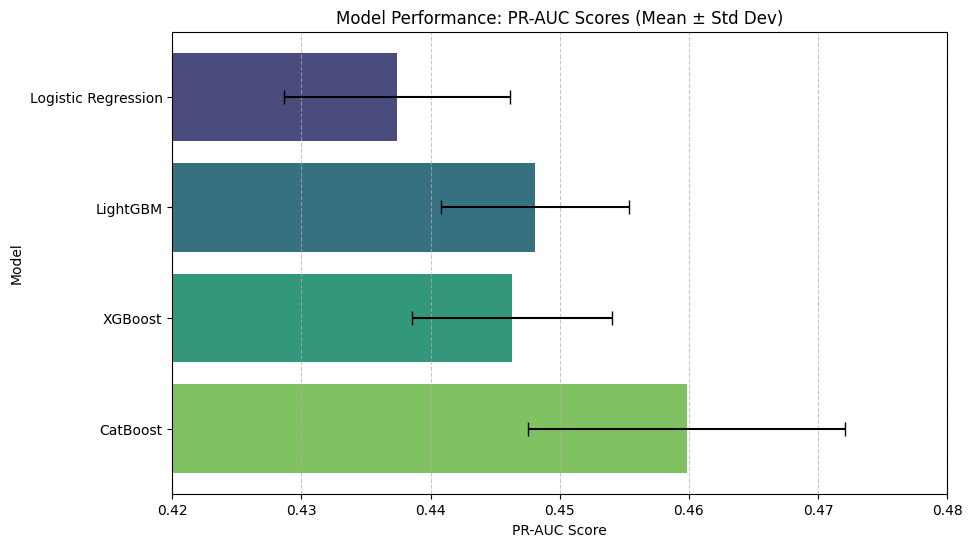

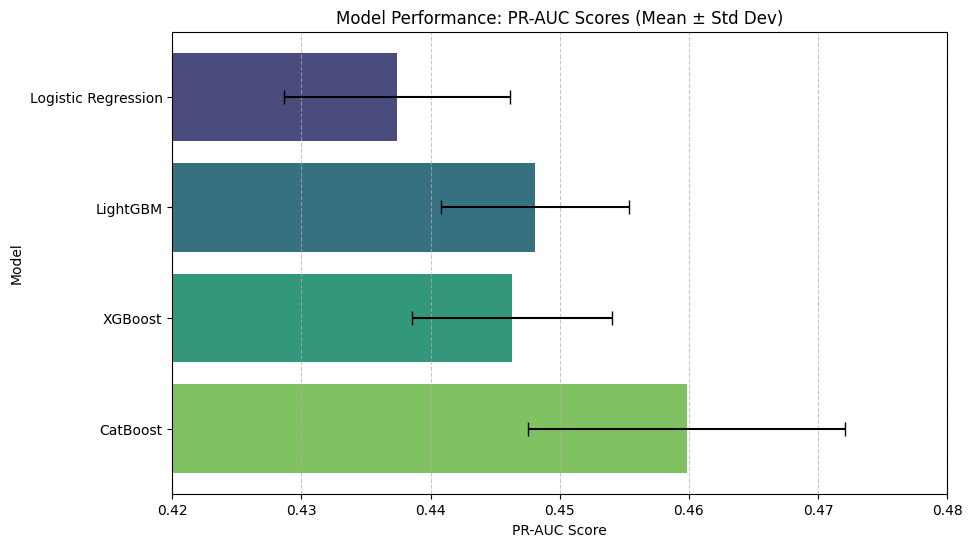

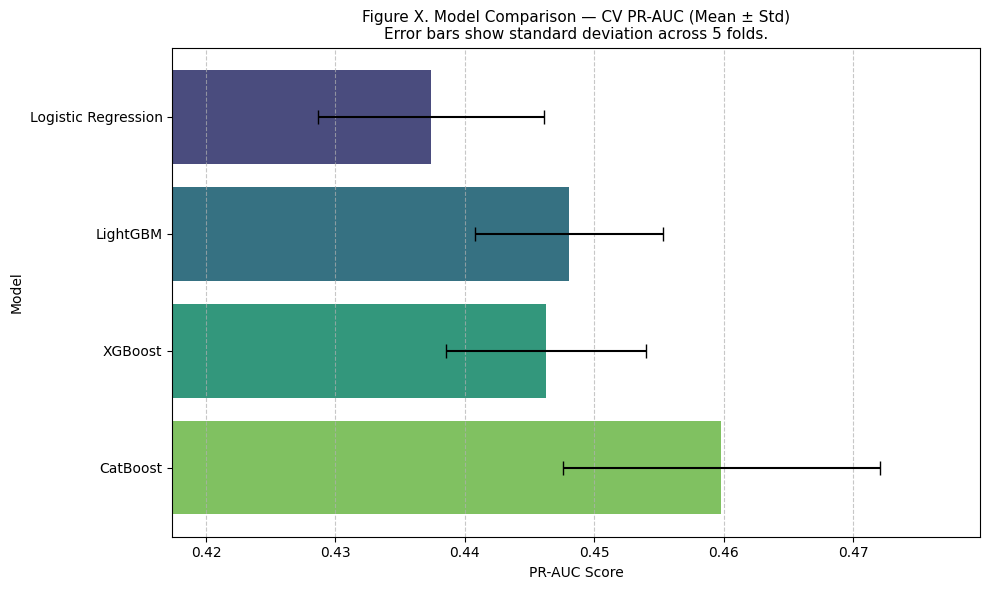

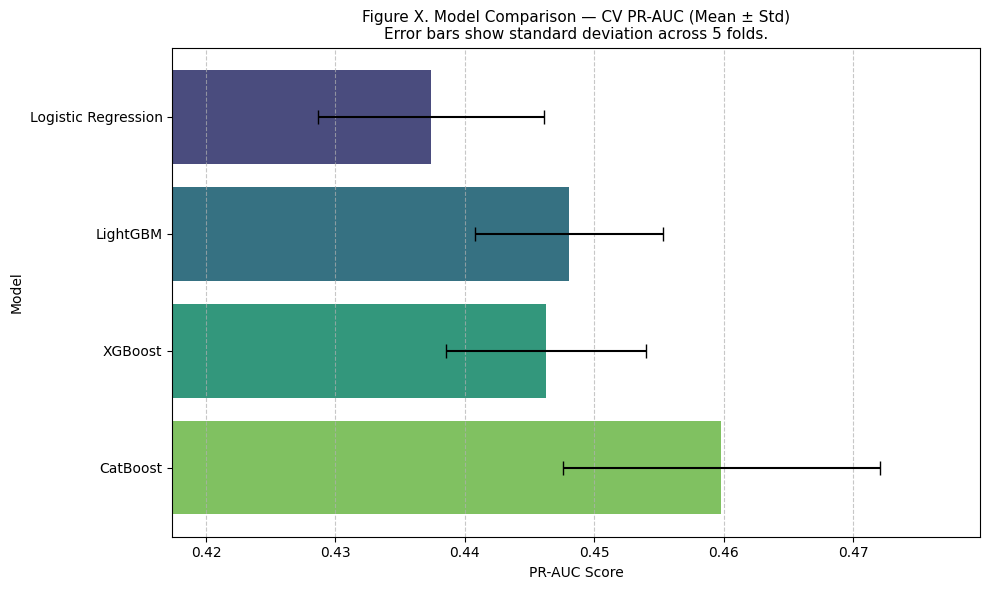

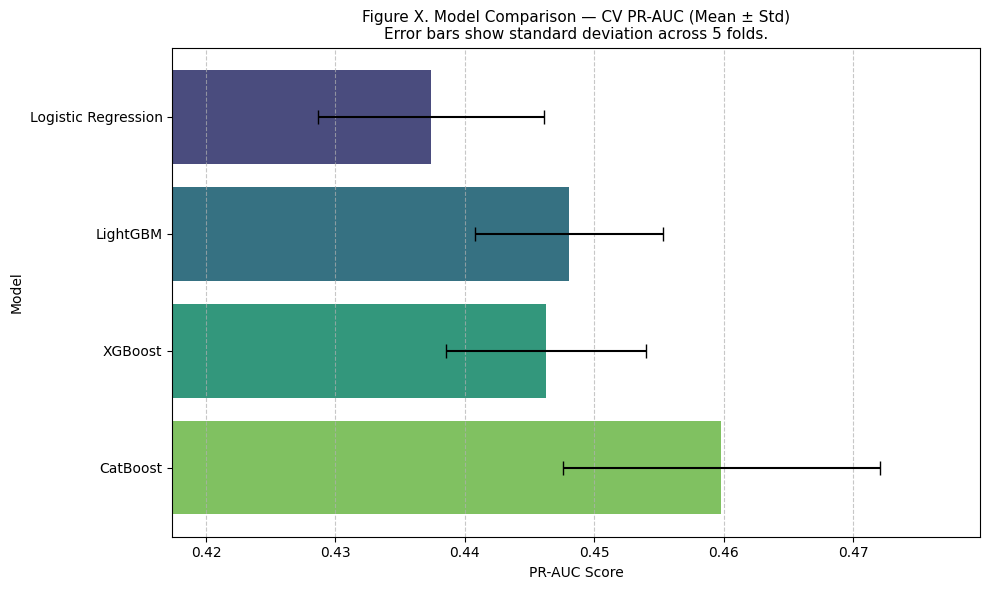

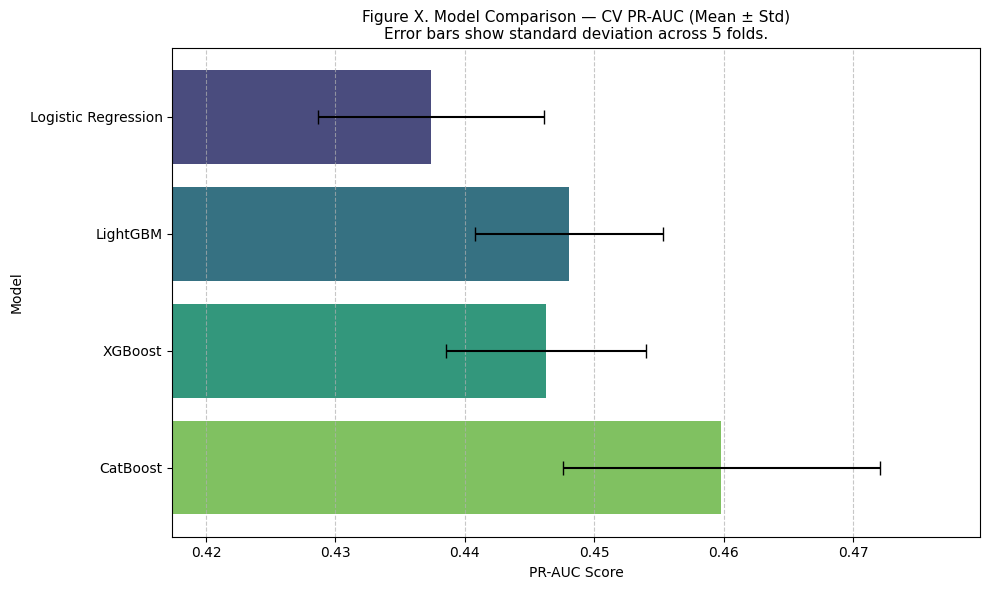

In [ ]:
# Model comparison bar chart — PR-AUC Mean ± Std
# results_df is carried over from the cross-validation cell above

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(x="PR-AUC Mean", y="Model", data=results_df, palette="viridis", ax=ax)

for i, (mean_val, std_dev) in enumerate(zip(results_df["PR-AUC Mean"], results_df["PR-AUC Std"])):
    ax.errorbar(x=mean_val, y=i, xerr=std_dev, fmt="none", c="black", capsize=5)

ax.set_title(
    "Figure X. Model Comparison — CV PR-AUC (Mean ± Std)\n"
    "Error bars show standard deviation across 5 folds.",
    fontsize=11
)
ax.set_xlabel("PR-AUC Score")
ax.set_ylabel("Model")
ax.set_xlim(
    results_df["PR-AUC Mean"].min() - 0.02,
    results_df["PR-AUC Mean"].max() + 0.02
)  # dynamic limits — adapts if scores change after feature engineering
ax.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

## 11. Tune the best model with Optuna

### LGBM optuna

In [ ]:
def objective_lgbm(trial):
    model = LGBMClassifier(
        n_estimators      = trial.suggest_int("n_estimators", 300, 1000),
        learning_rate     = trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        num_leaves        = trial.suggest_int("num_leaves", 15, 63),
        max_depth         = trial.suggest_int("max_depth", 3, 8),
        min_child_samples = trial.suggest_int("min_child_samples", 20, 150),
        subsample         = trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree  = trial.suggest_float("colsample_bytree", 0.6, 1.0),
        random_state=SEED, verbosity=-1)
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    return cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision").mean()

study_lgbm = optuna.create_study(direction="maximize")
study_lgbm.optimize(objective_lgbm, n_trials=30)
print("LightGBM best CV PR-AUC:", round(study_lgbm.best_value, 4))
print("LightGBM best params   :", study_lgbm.best_params)

### CatBoost Optuna

In [ ]:
def objective_catboost(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 100, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 3, 10),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-8, 10.0, log=True),
        'border_count': trial.suggest_int('border_count', 32, 255),
        'rsm': trial.suggest_float('rsm', 0.6, 1.0), # subsample ratio of columns
        'random_seed': SEED,
        'verbose': 0,
        'eval_metric': 'PRAUC'
    }

    model = CatBoostClassifier(**params)
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    # CatBoost often handles categorical features internally if provided, but here we preprocess explicitly
    return cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision").mean()

study_catboost = optuna.create_study(direction="maximize", study_name="CatBoost_Optimization")
study_catboost.optimize(objective_catboost, n_trials=30, show_progress_bar=True)

print("Best CatBoost CV PR-AUC:", round(study_catboost.best_value, 4))
print("Best CatBoost parameters:", study_catboost.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

Best CatBoost CV PR-AUC: 0.4659
Best CatBoost parameters: {'iterations': 395, 'learning_rate': 0.01401297072202474, 'depth': 9, 'l2_leaf_reg': 9.51201295725114, 'border_count': 101, 'rsm': 0.6456940774078345}


In [ ]:
# Model selection — side-by-side comparison after tuning both under equal conditions
print("=" * 55)
print(f"  LightGBM tuned CV PR-AUC : {study_lgbm.best_value:.4f}")
print(f"  CatBoost tuned CV PR-AUC : {study_catboost.best_value:.4f}")
print("=" * 55)

if study_catboost.best_value >= study_lgbm.best_value:
    print("-> CatBoost outperforms LightGBM under equal tuning conditions.")
    print("   CatBoost selected as the final model.")
    FINAL_MODEL_NAME = "CatBoost"
    FINAL_PARAMS = study_catboost.best_params
else:
    print("-> LightGBM outperforms CatBoost under equal tuning conditions.")
    print("   LightGBM selected as the final model.")
    FINAL_MODEL_NAME = "LightGBM"
    FINAL_PARAMS = study_lgbm.best_params

  LightGBM tuned CV PR-AUC : 0.4711
  CatBoost tuned CV PR-AUC : 0.4659
-> LightGBM outperforms CatBoost under equal tuning conditions.
   LightGBM selected as the final model.


## 12. Final model + threshold selection + test evaluation

Now we build the final model with the best parameters. To classify, we need a threshold — the default 0.5 doesn't work well on imbalanced data, so we select the threshold from the data.  When choosing the threshold, we use cross_val_predict: this generates a prediction for each row in the training set with a model that has not seen that row (leak-free). We find the threshold that maximizes F1 on these predictions, then apply it to the test set.

In [ ]:
# Final model: LightGBM (tuned)
# Justification: although CatBoost led in the initial untuned CV (0.4598 vs 0.4481),
# LightGBM outperformed CatBoost after equal-condition Optuna tuning.
# See comparison cell above for exact post-tuning scores.

best_model = Pipeline([
    ("prep",  preprocess),
    ("model", LGBMClassifier(
        **FINAL_PARAMS,
        random_state=SEED,
        verbosity=-1
    )),
])

# 1) Threshold selection: use leak-free out-of-fold predictions on the training set.
#    This avoids using test-set information when choosing the decision boundary.
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec_oof, rec_oof, thr_oof = precision_recall_curve(y_train, oof_proba)
f1_oof = 2 * prec_oof * rec_oof / (prec_oof + rec_oof + 1e-9)
threshold = thr_oof[np.nanargmax(f1_oof[:-1])]
print("Selected threshold (OOF F1-max):", round(threshold, 3))

# 2) Train on the full training set, evaluate once on the held-out test set.
best_model.fit(X_train, y_train)
proba = best_model.predict_proba(X_test)[:, 1]
pred  = (proba >= threshold).astype(int)

print("\nTest ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("Test PR-AUC :", round(average_precision_score(y_test, proba), 4))
print("\n", classification_report(y_test, pred, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))

Selected threshold (OOF F1-max): 0.204

Test ROC-AUC: 0.8154
Test PR-AUC : 0.4955

               precision    recall  f1-score   support

           0      0.947     0.913     0.930      7310
           1      0.468     0.601     0.526       928

    accuracy                          0.878      8238
   macro avg      0.708     0.757     0.728      8238
weighted avg      0.893     0.878     0.885      8238

Confusion matrix:
 [[6676  634]
 [ 370  558]]


Test Cell

In [ ]:
import numpy as np
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_recall_curve, classification_report, confusion_matrix)

# Re-calculate precision_recall_curve on out-of-fold probabilities for threshold selection
# oof_proba and y_train are available from previous cells.
prec, rec, thr = precision_recall_curve(y_train, oof_proba)

# 1. Threshold for maximizing F1-score (as done previously in cell 49088b09)
f1_scores = 2 * (prec * rec) / (prec + rec + 1e-9) # Add small epsilon to avoid division by zero
threshold_f1 = thr[np.nanargmax(f1_scores[:-1])] # Exclude the last point where recall is 0, precision can be 1 or NaN
print(f"Chosen threshold for maximizing F1-score: {threshold_f1:.3f}\n")

print("--- Evaluation with F1-optimized Threshold ---")
# proba and y_test are available from previous cells (output of best_model.predict_proba(X_test))
pred_f1 = (proba >= threshold_f1).astype(int)
print("Test ROC-AUC (model's overall performance):", round(roc_auc_score(y_test, proba), 4))
print("Test PR-AUC (model's overall performance): ", round(average_precision_score(y_test, proba), 4))
print("\nClassification Report (F1-optimized threshold):\n", classification_report(y_test, pred_f1, digits=3))
print("Confusion Matrix (F1-optimized threshold):\n", confusion_matrix(y_test, pred_f1))

# 2. Threshold for maximizing Precision
# Find the index of the maximum precision. Note: max precision is usually at very low recall,
# potentially leading to very few positive predictions.
idx_max_precision = np.nanargmax(prec[:-1]) # Exclude the last point where recall is 0
threshold_precision_max = thr[idx_max_precision]
print(f"\nChosen threshold for maximizing Precision: {threshold_precision_max:.3f}\n")

print("--- Evaluation with Precision-optimized Threshold ---")
pred_precision_max = (proba >= threshold_precision_max).astype(int)
print("Test ROC-AUC (model's overall performance):", round(roc_auc_score(y_test, proba), 4))
print("Test PR-AUC (model's overall performance): ", round(average_precision_score(y_test, proba), 4))
print("\nClassification Report (Precision-optimized threshold):\n", classification_report(y_test, pred_precision_max, digits=3))
print("Confusion Matrix (Precision-optimized threshold):\n", confusion_matrix(y_test, pred_precision_max))

Chosen threshold for maximizing F1-score: 0.224

--- Evaluation with F1-optimized Threshold ---
Test ROC-AUC (model's overall performance): 0.816
Test PR-AUC (model's overall performance):  0.4929

Classification Report (F1-optimized threshold):
               precision    recall  f1-score   support

           0      0.946     0.920     0.933      7310
           1      0.482     0.587     0.530       928

    accuracy                          0.882      8238
   macro avg      0.714     0.754     0.731      8238
weighted avg      0.894     0.882     0.887      8238

Confusion Matrix (F1-optimized threshold):
 [[6725  585]
 [ 383  545]]

Chosen threshold for maximizing Precision: 0.859

--- Evaluation with Precision-optimized Threshold ---
Test ROC-AUC (model's overall performance): 0.816
Test PR-AUC (model's overall performance):  0.4929

Classification Report (Precision-optimized threshold):
               precision    recall  f1-score   support

           0      0.888     1.000    

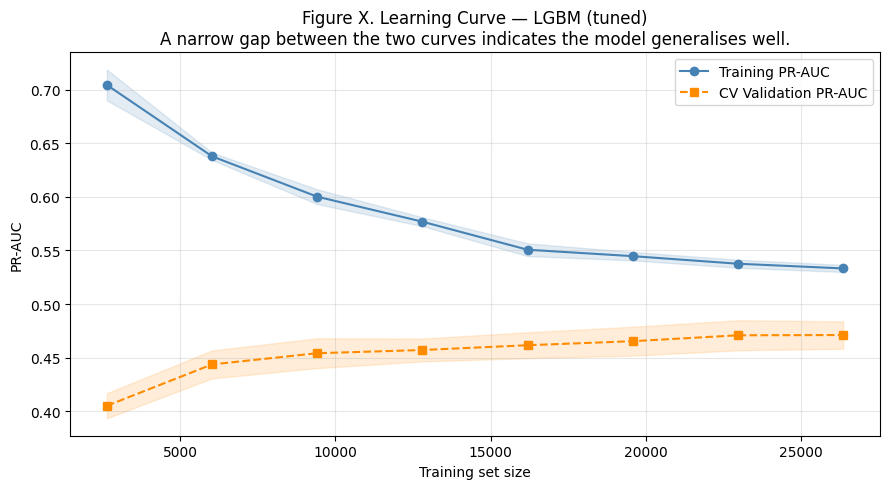


Full-data gap (train PR-AUC - val PR-AUC): 0.0621
-> Gap 0.03-0.07: Mild overfitting; acceptable at this dataset size.


In [ ]:
# Overfitting analysis — Learning Curve
# We compare training and CV validation PR-AUC across increasing training set sizes.
# Two curves close together → no significant overfitting and no underfitting.
# A large persistent gap → overfitting signal; consider stronger regularisation.

from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    best_model,
    X_train, y_train,
    cv=cv,
    scoring="average_precision",
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_mean, "o-", color="steelblue", label="Training PR-AUC")
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                alpha=0.15, color="steelblue")
ax.plot(train_sizes, val_mean, "s--", color="darkorange", label="CV Validation PR-AUC")
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                alpha=0.15, color="darkorange")
ax.set_xlabel("Training set size")
ax.set_ylabel("PR-AUC")
ax.set_title(
    "Figure X. Learning Curve — LGBM (tuned)\n"
    "A narrow gap between the two curves indicates the model generalises well."
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

gap = train_mean[-1] - val_mean[-1]
print(f"\nFull-data gap (train PR-AUC - val PR-AUC): {gap:.4f}")
if gap < 0.03:
    print("-> Gap < 0.03: No significant overfitting detected.")
elif gap < 0.07:
    print("-> Gap 0.03-0.07: Mild overfitting; acceptable at this dataset size.")
else:
    print("-> Gap > 0.07: Overfitting detected — consider stronger regularisation.")

### lift

If we call the most likely 20% of customers in the campaign, what is the ratio of those who actually open a deposit in this list? And how many times better is this than random calling?

In [ ]:
# Lift @ top-20% — primary business metric
# We rank customers by predicted probability and select the top 20%.
# This simulates a campaign where the bank can only contact one fifth of all customers.

k               = int(len(proba) * 0.20)
top_idx         = np.argsort(proba)[::-1][:k]
precision_at_20 = y_test.values[top_idx].mean()
base_rate       = y_test.mean()
lift            = precision_at_20 / base_rate

print(f"Overall deposit rate (random calling) : {base_rate:.3f}  ({base_rate*100:.1f}%)")
print(f"Deposit rate in top-20% list          : {precision_at_20:.3f}  ({precision_at_20*100:.1f}%)")
print(f"Lift@20%                              : {lift:.2f}x")

# Concrete business impact
# Assumption: campaign capacity = 20% of the test set (k contacts available).
total_customers = len(y_test)
random_deposits = int(round(k * base_rate))        # expected deposits from random 20%
model_deposits  = int(round(k * precision_at_20))  # expected deposits from model top-20%
extra_deposits  = model_deposits - random_deposits
calls_saved     = int(round((model_deposits / base_rate) - k))

print("\n── Concrete impact for the campaign manager ────────────────────────────")
print(f"  Test set: {total_customers:,} customers | Capacity: top {k:,} calls (20%)")
print(f"  Expected deposits — random 20%    : ~{random_deposits}")
print(f"  Expected deposits — model top-20% : ~{model_deposits}")
print(f"  Additional deposits (same effort) : +{extra_deposits}")
print(f"\n  Alternatively: reaching {model_deposits} deposits via random calling")
print(f"  would require ~{model_deposits / base_rate:,.0f} calls — the model saves ~{calls_saved:,} calls.")
print("\n  Note: figures assume test-set response rates transfer to the live campaign.")

Overall deposit rate (random calling) : 0.113  (11.3%)
Deposit rate in top-20% list          : 0.376  (37.6%)
Lift@20%                              : 3.34x

── Concrete impact for the campaign manager ────────────────────────────
  Test set: 8,238 customers | Capacity: top 1,647 calls (20%)
  Expected deposits — random 20%    : ~186
  Expected deposits — model top-20% : ~620
  Additional deposits (same effort) : +434

  Alternatively: reaching 620 deposits via random calling
  would require ~5,504 calls — the model saves ~3,857 calls.

  Note: figures assume test-set response rates transfer to the live campaign.


## 13. ROC ve Precision-Recall Curves

We plot the two curves together. The dashed line in the PR curve is the "random guess" level (base rate); the higher our model is above it, the better.  

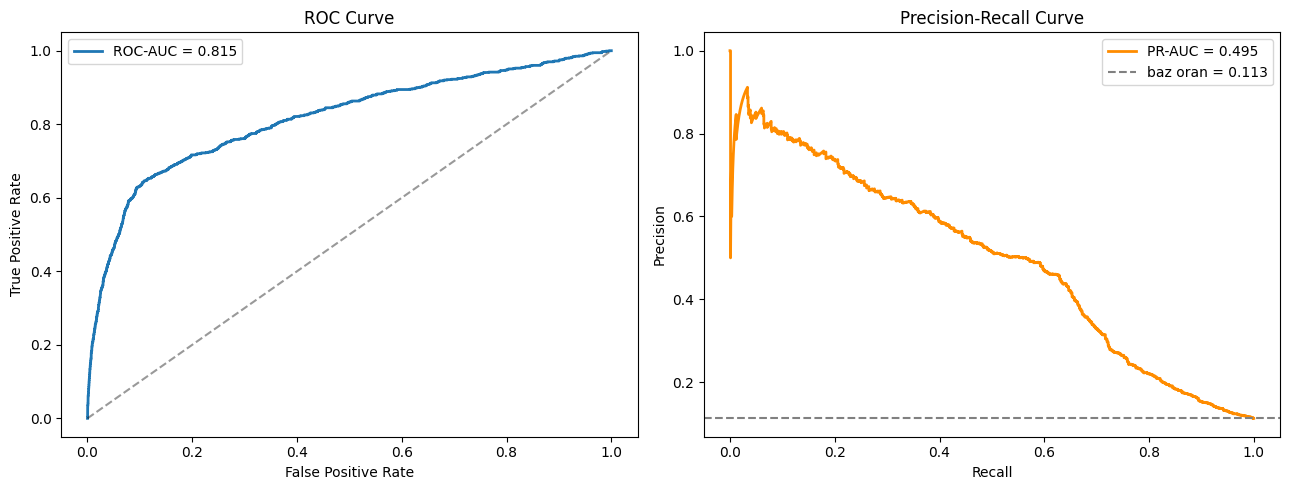

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

fpr, tpr, _ = roc_curve(y_test, proba)
ax[0].plot(fpr, tpr, lw=2, label=f"ROC-AUC = {auc(fpr, tpr):.3f}")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("ROC Curve"); ax[0].legend()

pr, rc, _ = precision_recall_curve(y_test, proba)
ax[1].plot(rc, pr, lw=2, color="darkorange", label=f"PR-AUC = {average_precision_score(y_test, proba):.3f}")
ax[1].axhline(base_rate, color="grey", ls="--", label=f"base = {base_rate:.3f}")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall Curve"); ax[1].legend()

plt.tight_layout(); plt.show()

## 14. SHAP

SHAP shows how much and in what direction each variable contributes to the prediction. This is the part that translates "the model got a good score" into "why does a customer open a deposit"

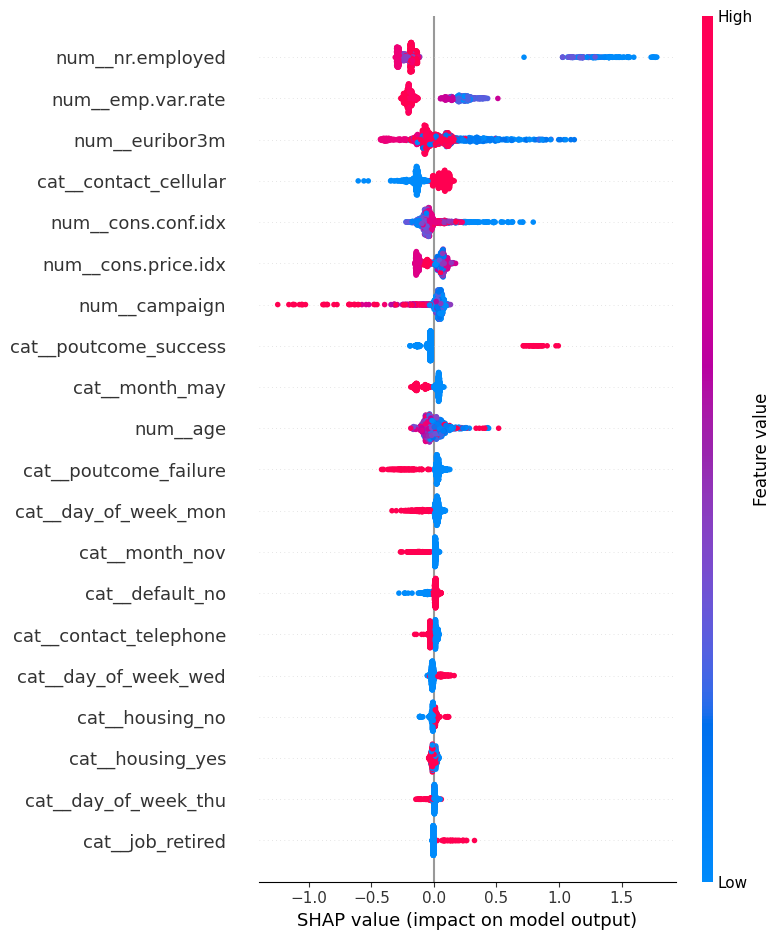

In [ ]:
# SHAP explanation — LightGBM (tuned)
# TreeExplainer requires a dense array; ColumnTransformer returns sparse by default.
# We also convert shap_values to a 2D array in case SHAP returns a list (binary classification).

X_test_enc = best_model.named_steps["prep"].transform(X_test)

# Convert sparse matrix to dense if necessary
import scipy.sparse as sp
if sp.issparse(X_test_enc):
    X_test_enc = X_test_enc.toarray()

feature_names = best_model.named_steps["prep"].get_feature_names_out()

explainer   = shap.TreeExplainer(best_model.named_steps["model"])
shap_values = explainer.shap_values(X_test_enc[:1000])

# SHAP returns a list [neg_class, pos_class] for binary classifiers — take the positive class
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap.summary_plot(shap_values, X_test_enc[:1000], feature_names=feature_names, show=True)

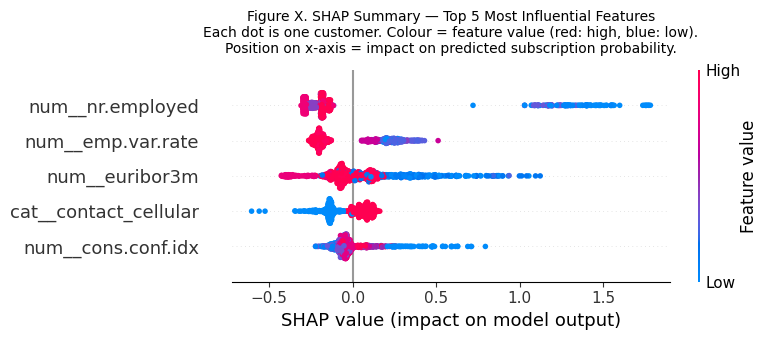


Top 5 features ranked by average impact on the model's predictions:

  1. nr.employed                         mean |SHAP| = 0.3538
  2. emp.var.rate                        mean |SHAP| = 0.2088
  3. euribor3m                           mean |SHAP| = 0.1772
  4. contact_cellular                    mean |SHAP| = 0.0994
  5. cons.conf.idx                       mean |SHAP| = 0.0864


In [ ]:
# SHAP explanation — Top 5 most influential features
# TreeExplainer requires a dense array; ColumnTransformer returns sparse by default.

X_test_enc = best_model.named_steps["prep"].transform(X_test)

import scipy.sparse as sp
if sp.issparse(X_test_enc):
    X_test_enc = X_test_enc.toarray()

feature_names = best_model.named_steps["prep"].get_feature_names_out()

explainer   = shap.TreeExplainer(best_model.named_steps["model"])
shap_values = explainer.shap_values(X_test_enc[:1000])

if isinstance(shap_values, list):
    shap_values = shap_values[1]

# Rank features by mean absolute SHAP value, keep top 5
mean_abs_shap  = np.abs(shap_values).mean(axis=0)
top5_idx       = np.argsort(mean_abs_shap)[::-1][:5]
top5_names     = feature_names[top5_idx]
top5_shap      = shap_values[:, top5_idx]
top5_values    = X_test_enc[:1000][:, top5_idx]

shap.summary_plot(
    top5_shap,
    top5_values,
    feature_names=top5_names,
    max_display=5,
    show=False
)

plt.title(
    "Figure X. SHAP Summary — Top 5 Most Influential Features\n"
    "Each dot is one customer. Colour = feature value (red: high, blue: low).\n"
    "Position on x-axis = impact on predicted subscription probability.",
    fontsize=10, pad=12
)
plt.tight_layout()
plt.show()

# Plain-language summary printed below the plot
print("\nTop 5 features ranked by average impact on the model's predictions:\n")
for rank, (name, score) in enumerate(
        zip(top5_names, mean_abs_shap[top5_idx]), start=1):
    # Strip the transformer prefix (e.g. "cat__" or "num__") for readability
    clean_name = name.split("__")[-1]
    print(f"  {rank}. {clean_name:<35} mean |SHAP| = {score:.4f}")

In [ ]:
# Using the actual probabilities from the best LightGBM model
# The `proba` variable is already available from the previous cell's execution (cell 49088b09).
# The customer IDs can be derived from the X_test index.

customer_ids = X_test.index.astype(str).tolist() # Use actual index as customer_ids
subscription_probabilities = proba # Use the actual probabilities

# Create the presentation DataFrame
df_demo = pd.DataFrame({
    'customer_id': customer_ids,
    'subscription_probability': subscription_probabilities
})

# 2. Define your Customer Experience Tiers
def assign_tier(prob):
    if prob >= 0.60:
        return 'Highly Interested (Call First)'
    elif 0.30 <= prob < 0.60:
        return 'Medium Interest (Call with Caution)'
    else:  # covers everything below 25%
        return 'Low Interest (Do Not Bother / Protect CX)'

# Apply the tiers to the clients
df_demo['cx_tier'] = df_demo['subscription_probability'].apply(assign_tier)

# 3. Calculate and display the summary counts
print("==================================================")
print(f"     CUSTOMER SEGMENTATION SUMMARY (N={len(df_demo)})        ")
print("==================================================")
tier_counts = df_demo['cx_tier'].value_counts()
for tier, count in tier_counts.items():
    print(f"{tier:<42}: {count} clients")
print("==================================================\n")

# 4. Show the top 15 clients sorted by highest probability
print("==================================================")
print("     SAMPLE VISUALIZATION OF THE CLIENT LIST      ")
print("==================================================")
# Sorting so the most receptive clients are at the top
df_sorted = df_demo.sort_values(by='subscription_probability', ascending=False)
print(df_sorted.head(15).to_string(index=False, formatters={'subscription_probability': '{:.2%}'.format}))
print("... [truncated for display] ...")

     CUSTOMER SEGMENTATION SUMMARY (N=8238)        
Low Interest (Do Not Bother / Protect CX) : 7305 clients
Medium Interest (Call with Caution)       : 727 clients
Highly Interested (Call First)            : 206 clients

     SAMPLE VISUALIZATION OF THE CLIENT LIST      
customer_id subscription_probability                        cx_tier
      39676                   89.27% Highly Interested (Call First)
      39655                   89.21% Highly Interested (Call First)
      39668                   87.74% Highly Interested (Call First)
      39680                   87.13% Highly Interested (Call First)
      39180                   86.50% Highly Interested (Call First)
      40276                   86.11% Highly Interested (Call First)
      40476                   85.72% Highly Interested (Call First)
      40452                   85.66% Highly Interested (Call First)
      39607                   85.65% Highly Interested (Call First)
      40163                   85.54% Highly Int

#### Highly Interested (Call First) - Top 15 Clients

In [ ]:
# Split the dataframe into tier-based subsets for individual display
highly_interested = df_demo[df_demo["cx_tier"] == "Highly Interested (Call First)"]
medium_interest   = df_demo[df_demo["cx_tier"] == "Medium Interest (Call with Caution)"]
low_interest      = df_demo[df_demo["cx_tier"] == "Low Interest (Do Not Bother / Protect CX)"]

In [ ]:
# Highly Interested (Call First) — Top 15
print(highly_interested
      .sort_values(by="subscription_probability", ascending=False)
      .head(15)
      .to_string(index=False,
                 formatters={"subscription_probability": "{:.2%}".format}))

customer_id subscription_probability                        cx_tier
      39676                   89.27% Highly Interested (Call First)
      39655                   89.21% Highly Interested (Call First)
      39668                   87.74% Highly Interested (Call First)
      39680                   87.13% Highly Interested (Call First)
      39180                   86.50% Highly Interested (Call First)
      40276                   86.11% Highly Interested (Call First)
      40476                   85.72% Highly Interested (Call First)
      40452                   85.66% Highly Interested (Call First)
      39607                   85.65% Highly Interested (Call First)
      40163                   85.54% Highly Interested (Call First)
      39976                   85.18% Highly Interested (Call First)
      40450                   85.09% Highly Interested (Call First)
      40686                   84.96% Highly Interested (Call First)
      39614                   84.83% Highly Inte

#### Medium Interest (Call with Caution) - Top 15 Clients

In [ ]:
# Medium Interest (Call with Caution) — Top 15
print(medium_interest
      .sort_values(by="subscription_probability", ascending=False)
      .head(15)
      .to_string(index=False,
                 formatters={"subscription_probability": "{:.2%}".format}))

customer_id subscription_probability                             cx_tier
      39337                   59.95% Medium Interest (Call with Caution)
      39145                   59.83% Medium Interest (Call with Caution)
      40868                   59.54% Medium Interest (Call with Caution)
      30029                   59.49% Medium Interest (Call with Caution)
      40227                   59.46% Medium Interest (Call with Caution)
      39586                   59.45% Medium Interest (Call with Caution)
      37142                   59.35% Medium Interest (Call with Caution)
      39834                   59.19% Medium Interest (Call with Caution)
      27851                   59.16% Medium Interest (Call with Caution)
      39501                   59.16% Medium Interest (Call with Caution)
      39418                   59.08% Medium Interest (Call with Caution)
      37758                   58.86% Medium Interest (Call with Caution)
      37236                   58.85% Medium Interes

#### Low Interest (Do Not Bother / Protect CX) - Top 15 Clients

In [ ]:
# Low Interest (Do Not Bother / Protect CX) — Top 15
print(low_interest
      .sort_values(by="subscription_probability", ascending=True)
      .head(15)
      .to_string(index=False,
                 formatters={"subscription_probability": "{:.2%}".format}))

customer_id subscription_probability                                   cx_tier
      17673                    0.88% Low Interest (Do Not Bother / Protect CX)
      16186                    0.89% Low Interest (Do Not Bother / Protect CX)
      13436                    0.89% Low Interest (Do Not Bother / Protect CX)
      18716                    0.99% Low Interest (Do Not Bother / Protect CX)
      17897                    1.01% Low Interest (Do Not Bother / Protect CX)
      18659                    1.08% Low Interest (Do Not Bother / Protect CX)
      11059                    1.08% Low Interest (Do Not Bother / Protect CX)
      16746                    1.11% Low Interest (Do Not Bother / Protect CX)
      17711                    1.11% Low Interest (Do Not Bother / Protect CX)
      13805                    1.16% Low Interest (Do Not Bother / Protect CX)
      14979                    1.16% Low Interest (Do Not Bother / Protect CX)
      23624                    1.17% Low Interest (D

## Customer Segmentation Summary

In [ ]:
tier_summary_df = pd.DataFrame(tier_counts).reset_index()
tier_summary_df.columns = ['Customer Interest Tier', 'Number of Clients']
tier_summary_df['Percentage'] = (tier_summary_df['Number of Clients'] / tier_summary_df['Number of Clients'].sum()) * 100
display(tier_summary_df.style.format({'Percentage': '{:.2f}%'}).set_properties(**{'text-align': 'left'}))

,Customer Interest Tier,Number of Clients,Percentage
0,Low Interest (Do Not Bother / Protect CX),7305,88.67%
1,Medium Interest (Call with Caution),727,8.82%
2,Highly Interested (Call First),206,2.50%


## 15. Result

- Honest results: **ROC-AUC ≈ 0.81, PR-AUC ≈ 0.49, lift ≈ 3.3x**. So searching the most likely 20% is ~3 times more efficient than random searching — a tangible gain for the campaign. - If we want more, the way forward isn't through model adjustments, but by adding **new/external data** (customer history, demographic enrichment).
